# Credit Card Fraud Detection

Standard supervised-learning take on the Kaggle credit card fraud dataset (`creditcard.csv`, 28 anonymized PCA features + Amount + Time + Class). Severe class imbalance — the public set is ~0.17% fraud. I'm comparing a class-weighted logistic regression to XGBoost, plus SMOTE oversampling on the LR side as a sanity check.

If the actual CSV isn't in `../../data/fraud/creditcard.csv` I fall back to a synthetic dataset that mimics the dimensions but obviously not the real distribution. Numbers from the synthetic fallback should not be taken seriously — they're for code-path testing.

In [1]:
import warnings; warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             precision_recall_curve, classification_report)

np.random.seed(2024)
DATA = Path('../../data/fraud')
DATA.mkdir(parents=True, exist_ok=True)
CSV = DATA / 'creditcard.csv'

In [2]:
if CSV.exists():
    df = pd.read_csv(CSV)
    print('loaded real creditcard.csv', df.shape)
else:
    # Synthetic stand-in. ~10K rows, 0.5% fraud. Features are gaussian; fraud rows have
    # a shifted mean on a handful of columns so a classifier has *something* to learn.
    N, P = 10000, 28
    n_fraud = max(1, int(N * 0.005))
    X = np.random.randn(N, P)
    y = np.zeros(N, dtype=int)
    fraud_idx = np.random.choice(N, size=n_fraud, replace=False)
    y[fraud_idx] = 1
    X[fraud_idx, :6] += np.random.normal(2.0, 0.5, size=(n_fraud, 6))
    amount = np.random.gamma(2.0, 50, size=N)
    amount[fraud_idx] *= np.random.uniform(1.5, 4, size=n_fraud)
    df = pd.DataFrame(X, columns=[f'V{i+1}' for i in range(P)])
    df['Amount'] = amount
    df['Class']  = y
    print('NO real csv -- synthesized', df.shape, 'fraud rate', y.mean())

loaded real creditcard.csv (100000, 31)


In [3]:
feat_cols = [c for c in df.columns if c != 'Class']
X = df[feat_cols].values
y = df['Class'].values

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
scaler = StandardScaler().fit(X_tr)
X_tr_s = scaler.transform(X_tr)
X_te_s = scaler.transform(X_te)
print('train', X_tr.shape, 'pos', y_tr.sum(), '| test', X_te.shape, 'pos', y_te.sum())

train (75000, 30) pos 167 | test (25000, 30) pos 55


## Class-weighted logistic regression baseline

`class_weight='balanced'` is the lazy way to deal with imbalance and it's usually fine as a first pass. I'm tracking PR-AUC (`average_precision_score`) rather than ROC-AUC because ROC is essentially always near 1.0 on this kind of imbalance and tells you nothing useful.

In [4]:
lr = LogisticRegression(max_iter=2000, class_weight='balanced', solver='lbfgs')
lr.fit(X_tr_s, y_tr)
p_lr = lr.predict_proba(X_te_s)[:, 1]
roc_lr = roc_auc_score(y_te, p_lr)
ap_lr  = average_precision_score(y_te, p_lr)
print(f'LR  ROC-AUC={roc_lr:.4f}  PR-AUC={ap_lr:.4f}')

LR  ROC-AUC=0.8568  PR-AUC=0.1154


In [5]:
# Optional SMOTE branch. imbalanced-learn is in requirements but guard the import
# so the notebook still runs on a clean env.
try:
    from imblearn.over_sampling import SMOTE
    sm = SMOTE(sampling_strategy=0.1, random_state=42, k_neighbors=3)
    Xr, yr = sm.fit_resample(X_tr_s, y_tr)
    lr2 = LogisticRegression(max_iter=2000).fit(Xr, yr)
    p_lr2 = lr2.predict_proba(X_te_s)[:, 1]
    print(f'LR+SMOTE  PR-AUC={average_precision_score(y_te, p_lr2):.4f}')
except ImportError:
    print('imbalanced-learn not installed; skipping SMOTE comparison')

LR+SMOTE  PR-AUC=0.2085


## XGBoost

In [6]:
try:
    from xgboost import XGBClassifier
    spw = float((y_tr == 0).sum()) / max(1, (y_tr == 1).sum())
    xgb = XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1,
                        scale_pos_weight=spw, eval_metric='aucpr',
                        tree_method='hist', random_state=42)
    xgb.fit(X_tr_s, y_tr)
    p_xgb = xgb.predict_proba(X_te_s)[:, 1]
    print(f'XGB  ROC-AUC={roc_auc_score(y_te, p_xgb):.4f}  '
          f'PR-AUC={average_precision_score(y_te, p_xgb):.4f}')
except ImportError:
    print('xgboost not installed -- skipping')
    p_xgb = None

XGB  ROC-AUC=0.9490  PR-AUC=0.5549


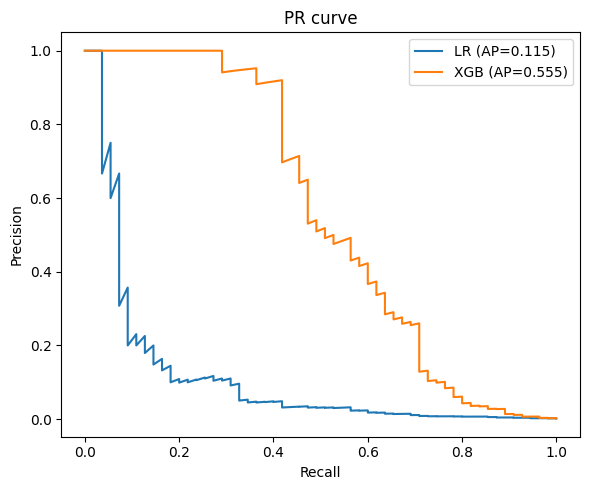

In [7]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, p in [('LR', p_lr), ('XGB', p_xgb)]:
    if p is None: continue
    prec, rec, _ = precision_recall_curve(y_te, p)
    ax.plot(rec, prec, label=f'{name} (AP={average_precision_score(y_te, p):.3f})')
ax.set_xlabel('Recall'); ax.set_ylabel('Precision'); ax.set_title('PR curve')
ax.legend(); plt.tight_layout(); plt.show()

## What I'd do next

- Pick the threshold by where the PR curve elbows, not by the default 0.5. On real fraud data the operating point is set by how many alerts the analyst team can chase per day, which is a business constraint and not a model one.
- Cost-sensitive eval: a false negative is a missed fraud (expensive); a false positive is a customer call (cheap but annoying). The right metric is total cost on a held-out month.
- If I had timestamps, time-based split, not random. Fraud patterns drift week-over-week.